# 13. Burgers with a steep front: map methods vs classical schemes
Same method as notebook 12 (backward map, Taylor predictor, adjoint split, greedy), with **α = 0.01** so a near-shock forms (max $|u_x|\approx 18$ by $t\approx0.4$, near $x\approx0.87$). No RL here: only the rules, against the classical schemes people use.

In [1]:
%matplotlib inline
import os, heapq, itertools, time, warnings
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

### PDE, grid and exact solution
$u_t + u u_x = \alpha u_{xx}$ on $[0,1]$, $u=0$ at the walls, $u_0=\sin\pi x+\tfrac12\sin2\pi x$, $\alpha=0.01$.
- **Time step**: explicit LW / FD-3 need $2r+\nu^2\le1$ ($r=\alpha\Delta t/\Delta x^2$, $\nu=a\Delta t/\Delta x$). With small α the advective part matters, so Δt comes from this combined rule (0.9 for margin).
- **Exact solution**: Hopf–Cole as a weighted average, $u=\int\frac{x-y}{t}W\,dy\big/\int W\,dy$, $W=e^{-F_0(y)/2\alpha-(x-y)^2/4\alpha t}$, with mirror images for the walls. The cosine series of notebook 12 loses all accuracy at α = 0.01; this form does not.
- **Check**: an explicit FD solve on finer and finer grids must converge to it at 2nd order (error ÷4 per halving).

nx = 100, nt = 181, dx = 0.01010, dt = 3.333e-03, nu_max = 0.49, r = 0.33
check: FD on a grid 1x finer vs u_true at t = 0.30: max error 1.7e-02
check: FD on a grid 2x finer vs u_true at t = 0.30: max error 4.2e-03
check: FD on a grid 4x finer vs u_true at t = 0.30: max error 1.1e-03


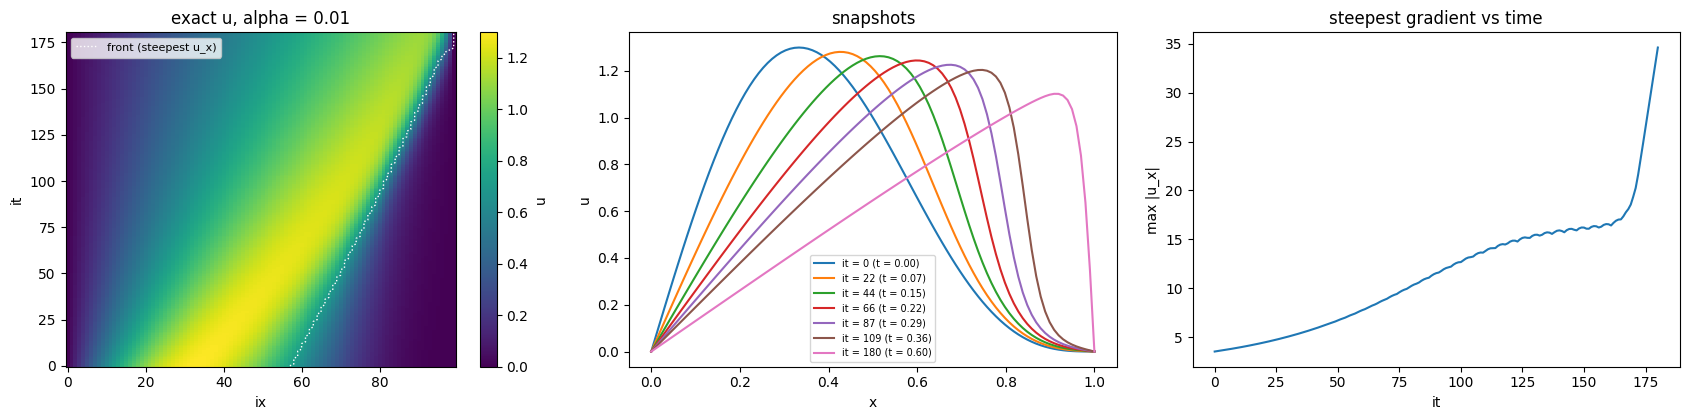

In [2]:
# ── PDE:  u_t + u u_x = alpha u_xx  on [0, 1],  u = 0 at both walls.  alpha = 0.01: a steep front forms ──
alpha = 0.01
a     = lambda u: u                            # advection speed: Burgers
A_MAX = 1.5                                    # bound on |u| (the IC peaks at about 1.26), for the CFL limit
u0    = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)
F0    = lambda x: (1 - np.cos(np.pi * x)) / np.pi + (1 - np.cos(2 * np.pi * x)) / (4 * np.pi)   # integral of u0 from 0 to x

# ── Grid ──
nx, T = 100, 0.6
dx = 1.0 / (nx - 1)
# explicit stability for advection + diffusion (LW, FD-3): 2r + nu^2 <= 1, with r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
c2, c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-c1 + np.sqrt(c1**2 + 4 * c2 * 0.9)) / (2 * c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole) as a weighted average: stays accurate for small alpha (the cosine series does not) ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),
#    on a uniform y grid over [-1, 2]: F0 is mirrored about 0 and 1 (the walls). Exponents shifted by their max.
_Y  = np.linspace(-1.0, 2.0, 30001)
_FY = F0(np.where(_Y < 0, -_Y, np.where(_Y > 1, 2 - _Y, _Y))) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the whole grid, once (u_true ONLY for checking and reporting, never for building)
U_GRID = np.array([u_true(x_grid, it * dt) for it in range(nt)])     # (it, ix)
Ug = lambda q: U_GRID[q[1], q[0]]

print(f"nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e}, nu_max = {A_MAX * dt / dx:.2f}, r = {alpha * dt / dx**2:.2f}")
# check: an explicit FD solve on finer and finer grids must converge to u_true (2nd order: error / 4 per halving)
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / (0.2 * h**2 / alpha))); s = t_end / steps
    u = u0(np.arange(n) * h)
    for _ in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - u[1:-1] * s / (2 * h) * (u[2:] - u[:-2])
    return u[::k]
_it = nt // 2
for k in (1, 2, 4):
    print(f"check: FD on a grid {k}x finer vs u_true at t = {_it * dt:.2f}: max error {np.abs(_fd_fine(k, _it * dt) - U_GRID[_it]).max():.1e}")

Ux = np.gradient(U_GRID, dx, axis=1)
FRONT_IX = np.argmin(Ux, axis=1)                                      # steepest point (front) at each level
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
im = axes[0].pcolormesh(np.arange(nx), np.arange(nt), U_GRID, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u"); axes[0].plot(FRONT_IX, np.arange(nt), "w:", lw=1, label="front (steepest u_x)")
axes[0].set_xlabel("ix"); axes[0].set_ylabel("it"); axes[0].legend(fontsize=8); axes[0].set_title(f"exact u, alpha = {alpha}")
for it in [0, 22, 44, 66, 87, 109, nt - 1]:
    axes[1].plot(x_grid, U_GRID[it], label=f"it = {it} (t = {it * dt:.2f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(np.arange(nt), -Ux.min(axis=1)); axes[2].set_xlabel("it"); axes[2].set_ylabel("max |u_x|")
axes[2].set_title("steepest gradient vs time")
plt.tight_layout(); plt.show()

### Taylor predictor
Unchanged from notebook 12. Check: 3 points one level down = Lax–Wendroff.

In [3]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

a_p = 1.0
r_, nu_ = alpha * dt / dx**2, a_p * dt / dx
print("3 points one level down:", np.round(solve_weights(np.array([-1, 0, 1]) * dx, np.array([-1, -1, -1]) * dt, a_p), 5))
print("Lax-Wendroff weights:   ", np.round([r_ + nu_/2 + nu_**2/2, 1 - 2*r_ - nu_**2, r_ - nu_/2 + nu_**2/2], 5))

3 points one level down: [0.54615 0.2377  0.21615]
Lax-Wendroff weights:    [0.54615 0.2377  0.21615]


### Score
Unchanged. Checked against the true local error with **exact** derivatives, separately **on the front** and **away from it**: the Taylor estimate is expected to degrade at the front.

front (|ix - front| <= 2)   : corr(log score, log error) = 0.86, median |score - error| / error = 0.34
smooth (|ix - front| >= 15) : corr(log score, log error) = 0.94, median |score - error| / error = 0.03


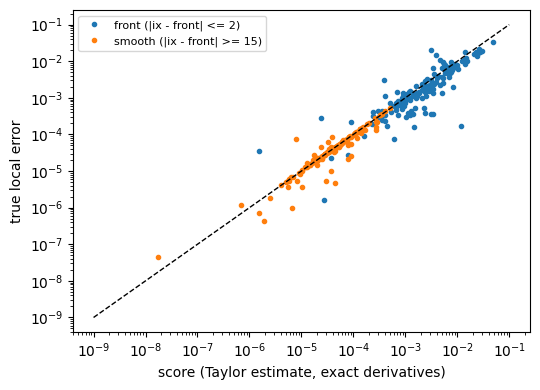

In [4]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=1e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs true local error, with EXACT derivatives, at points ON the front and AWAY from it ──
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]
res = {"front (|ix - front| <= 2)": [], "smooth (|ix - front| >= 15)": []}
while min(len(v) for v in res.values()) < 150:
    it = int(rng.integers(40, nt - 10))
    ix = int(rng.integers(5, nx - 5))
    dist = abs(ix - FRONT_IX[it])
    key = "front (|ix - front| <= 2)" if dist <= 2 else "smooth (|ix - front| >= 15)" if dist >= 15 else None
    if key is None or len(res[key]) >= 150:
        continue
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, it * dt), ix * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    true = abs(U_GRID[it, ix] - w @ np.array([U_GRID[it + q[1], ix + q[0]] for q in nb]))
    res[key].append((score(DX, DT, w, d), true))
fig, ax = plt.subplots(figsize=(5.5, 4))
for key, v in res.items():
    v = np.array(v)
    print(f"{key:28s}: corr(log score, log error) = {np.corrcoef(np.log(v[:, 0]), np.log(v[:, 1]))[0, 1]:.2f}, "
          f"median |score - error| / error = {np.median(np.abs(v[:, 0] - v[:, 1]) / v[:, 1]):.2f}")
    ax.loglog(v[:, 0], v[:, 1], ".", label=key)
lim = [1e-9, 1e-1]; ax.loglog(lim, lim, "k--", lw=1)
ax.set_xlabel("score (Taylor estimate, exact derivatives)"); ax.set_ylabel("true local error"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Guess (coarse solve)
LW on a grid **2× coarser** (`K_COARSE = 2`; 5× is too coarse for the front), then a **quintic spline** in x at each coarse time. The sine series of notebook 12 rings around the front and corrupts the derivatives everywhere; the spline stays local. Check: guess error on and off the front.

In [5]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the IC to T; then a quintic spline in x at each coarse time.
# (A global sine series rings around the front and pollutes the derivatives everywhere; the spline stays local.)
from scipy.interpolate import make_interp_spline
K_COARSE = 2
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))   # same stability rule as the grid
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for _ in tc[1:]:
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0] = n[-1] = 0.0
    Uc.append(n)
G_COARSE = len(xc) * len(tc)

Dc = np.zeros((5, len(tc), nx))                                   # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f_ = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f_) * Dc[:, jj] + f_ * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]

# ── Check: guess vs exact, on the front and away from it (u_true ONLY for this check) ──
print(f"coarse grid: {len(xc)} x {len(tc)} = {G_COARSE} points (dx {hc:.4f}, dt {tau:.2e})")
for name, sel in [("front", lambda it, ix: abs(ix - FRONT_IX[it]) <= 2), ("smooth", lambda it, ix: abs(ix - FRONT_IX[it]) >= 15)]:
    pts = [(ix, it) for it in range(40, nt, 6) for ix in range(5, nx - 5, 3) if sel(it, ix)]
    ex = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
    gs = np.array([guess_derivs(q) for q in pts])
    rel = np.median(np.abs(gs - ex) / (np.abs(ex) + 1e-12), axis=0)
    print(f"{name:6s}: median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.2f}" for v in rel))

coarse grid: 50 x 67 = 3350 points (dx 0.0204, dt 9.09e-03)
front : median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: 0.15  0.08  0.63  0.45  0.57
smooth: median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: 0.02  0.01  0.16  0.14  0.11


### Map machinery
As in notebook 12, plus:
- `weights` solved in a fixed order (the pick-order fix);
- `evaluate_live`: the forward pass with each point's speed taken from **computed** values (predict with the build weights, set $a$ = prediction, re-solve the weights; 1 or 2 Picard steps), as FD schemes do. With the guessed speed, a few % of speed error accumulates over 120 levels;
- `report` gives both errors.

Queries at $t = 0.4$: one **on the front**, one in the **smooth** region.

In [6]:
# ── Known data: the initial condition and the walls ──
U0 = u_true(x_grid, 0.0)
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = lambda q: U0[q[0]] if q[1] == 0 else 0.0

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs, with p's guessed speed; None if not admissible.
    Solved in the window order (latest level first, then left to right), so admissibility is
    bit-identical to admissible(p) whatever order the neighbours come in."""
    offs  = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    order = sorted(range(len(offs)), key=lambda i: (-offs[i][1], offs[i][0]))
    key   = (tuple(offs[i] for i in order), a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in key[0]]) * dx, np.array([o[1] for o in key[0]]) * dt, key[1])
    w = _w_cache[key]
    if w is None:
        return None
    out = np.empty(len(offs)); out[order] = w
    return out

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))

# ── The map, built backward from z*, latest t first ──
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down: beta_q += beta_p * w_q."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if is_known(q):
            continue
        if q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
        m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

def evaluate(m):
    """Forward pass: values bottom-up from the IC and walls, with the weights chosen in the map."""
    u_hat = {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):
        nbs, w = m["stencil"][p]
        u_hat[p] = sum(wq * value(q) for q, wq in zip(nbs, w))
    return u_hat

def evaluate_live(m, picard=1):
    """Forward pass with each point's speed taken from COMPUTED values (as FD schemes do), keeping the map's stencils.
    Predict with the build weights, set a = that prediction, re-solve the weights; repeat `picard` times.
    (The exact identity e = sum beta delta then only holds approximately: beta used the build weights.)"""
    u_hat = {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):
        nbs, w = m["stencil"][p]
        v  = np.array([value(q) for q in nbs])
        up = w @ v
        DX = np.array([q[0] - p[0] for q in nbs]) * dx
        DT = np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w2 = solve_weights(DX, DT, a(up))
            if w2 is None:
                break                                      # not admissible at this speed: keep the last value
            up = w2 @ v
        u_hat[p] = up
    return u_hat

def report(m):
    """points, true error at z* (guessed speed; computed speed with 1 and 2 Picard steps), exact bound (build weights)."""
    z = m["z_star"]
    bound = sum(abs(m["beta"][p] * (Ug(p) - w @ np.array([Ug(q) for q in nbs]))) for p, (nbs, w) in m["stencil"].items())
    return dict(points=len(m["stencil"]), error_guess=abs(Ug(z) - evaluate(m)[z]),
                error_live1=abs(Ug(z) - evaluate_live(m, 1)[z]), error_live2=abs(Ug(z) - evaluate_live(m, 2)[z]), bound=bound)

lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]

# ── Queries: one ON the front, one in the smooth region, at the same time ──
IT_Q = round(0.4 / dt)                                                 # t = 0.40, after the front has formed
Z_FRONT  = (int(FRONT_IX[IT_Q]), IT_Q)
Z_SMOOTH = (30, IT_Q)
print(f"front query {Z_FRONT} (x = {Z_FRONT[0] * dx:.3f}, u = {Ug(Z_FRONT):.3f}), smooth query {Z_SMOOTH} (u = {Ug(Z_SMOOTH):.3f})")

# ── Check: exact identity e(z*) = sum beta delta, with the LW stencil everywhere ──
m = build_map(Z_FRONT, lw)
err = Ug(Z_FRONT) - evaluate(m)[Z_FRONT]
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
print(f"LW map at the front: {len(m['stencil'])} points, error {abs(err):.2e} | identity: {err:.6e} vs {sum(m['beta'][p] * delta[p] for p in delta):.6e}")

front query (86, 120) (x = 0.869, u = 0.610), smooth query (30, 120) (u = 0.532)
LW map at the front: 8027 points, error 1.22e-01 | identity: 1.222525e-01 vs 1.222525e-01


### Window, admissible stencils, rules
Unchanged: 21-cell window, lowest score, LW reference, greedy (vectorised, counts new points correctly).

In [7]:
R_X, K_T = 3, 3
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5
TERMS   = list(taylor_coeffs((0.0,) * 5))

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

def situation(p):
    return (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))

_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cached by local situation and guessed speed."""
    key = situation(p)
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

_ref_cache = {}
def reference(z):
    """(score sum, points) of LW's map: the units of the return."""
    if z not in _ref_cache:
        m = build_map(z, lw)
        _ref_cache[z] = (sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"]), len(m["stencil"]))
    return _ref_cache[z]

def greedy_rule(lam):
    """Best one-step reward at every point: accuracy + lam * new points (vectorised over all admissible stencils)."""
    def choose(m, p):
        B_ref, N_ref = reference(m["z_star"])
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / B_ref + lam * (uses.astype(float) @ new) / N_ref
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

### Classical schemes
On grids refined 1–4×, from the exact IC to $t^*$:
- **FD-3** (central + Euler), **LW**, **CN** (linearised Crank–Nicolson): 2nd order;
- **FD-5 + RK4**: 4th-order central differences, RK4;
- **WENO5 + RK3**: the standard for Burgers with fronts/shocks. WENO5-JS (Jiang–Shu) with Lax–Friedrichs splitting for $(u^2/2)_x$, 4th-order central for $\alpha u_{xx}$, SSP-RK3. Walls by odd reflection (exact for Burgers).

**Evaluated points** = grid values computed in $z^*$'s dependency cone (× stages for RK).

In [8]:
def _weno5(vm2, vm1, v0, vp1, vp2):
    """WENO5-JS value at the interface on the vp1 side of v0, from the 5 values vm2 .. vp2 (arrays)."""
    q0 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6
    q1 = (-vm1 + 5 * v0 + 2 * vp1) / 6
    q2 = (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def weno_rhs(u, h):
    """du/dt for Burgers on nodes 0..n-1 with u = 0 at both walls:
    WENO5-JS (finite-difference form, Lax-Friedrichs flux splitting) for (u^2/2)_x, 4th-order central for alpha u_xx.
    Ghost nodes by odd reflection about each wall, which is exact for Burgers with u = 0 there."""
    n = len(u)
    ue = np.r_[-u[3:0:-1], u, -u[-2:-5:-1]]                  # ue[j] = node j - 3
    am = np.abs(u).max()
    fp = 0.5 * (0.5 * ue**2 + am * ue)
    fm = 0.5 * (0.5 * ue**2 - am * ue)
    j = np.arange(2, n + 3)                                   # interfaces i+1/2 for nodes i = -1 .. n-1  (j = i + 3)
    F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
    conv = -(F[1:] - F[:-1]) / h                              # node i: F_{i+1/2} - F_{i-1/2}
    c = np.arange(3, n + 3)
    diff = alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    du = conv + diff
    du[0] = du[-1] = 0.0
    return du

def classical(scheme, k, z):
    """Error at z* and evaluated points (grid values in z*'s dependency cone) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    x_star, t_star = z[0] * dx, z[1] * dt
    ix, u = z[0] * k, u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":                                     # its own stable step: CFL 0.4, diffusion number 0.2
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha)))
        s_ = t_star / steps
        for _ in range(steps):
            u1 = u + s_ * weno_rhs(u, h)
            u2 = 0.75 * u + 0.25 * (u1 + s_ * weno_rhs(u1, h))
            u  = u / 3 + 2 / 3 * (u2 + s_ * weno_rhs(u2, h))
        pts = 3 * sum(min(n - 2, ix + 9 * j) - max(1, ix - 9 * j) + 1 for j in range(steps))   # 3 stages, cone +3 per stage
        return pts, abs(u[ix] - u_true(x_star, t_star)[0])
    tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2
    steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    d2 = lambda v: np.r_[0, v[2:] - 2 * v[1:-1] + v[:-2], 0]
    d1 = lambda v: np.r_[0, v[2:] - v[:-2], 0] / 2
    def d4(v):
        a2, a1 = d2(v), d1(v)
        a2[2:-2] = (-v[4:] + 16 * v[3:-1] - 30 * v[2:-2] + 16 * v[1:-3] - v[:-4]) / 12
        a1[2:-2] = (-v[4:] + 8 * v[3:-1] - 8 * v[1:-3] + v[:-4]) / 12
        return a2, a1
    for _ in range(steps):
        nu = a(u) * tau_k / h
        if scheme == "FD-3":
            u = u + r * d2(u) - nu * d1(u)
        elif scheme == "LW":
            u = u + (r + nu**2 / 2) * d2(u) - nu * d1(u)
        elif scheme == "FD-5 + RK4":
            f = lambda v: (lambda a2, a1: r * a2 - a(v) * tau_k / h * a1)(*d4(v))
            k1 = f(u); k2 = f(u + k1 / 2); k3 = f(u + k2 / 2); k4 = f(u + k3)
            u = u + (k1 + 2 * k2 + 2 * k3 + k4) / 6
        elif scheme == "CN":
            lo, di, up = -r / 2 - nu[1:-1] / 4, (1 + r) * np.ones(n - 2), -r / 2 + nu[1:-1] / 4
            ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], di, lo[1:]
            u = np.r_[0, solve_banded((1, 1), ab, (u + r / 2 * d2(u) - nu / 2 * d1(u))[1:-1]), 0]
        u[0] = u[-1] = 0.0
    err = abs(u[ix] - u_true(x_star, t_star)[0])
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8}.get(scheme)
    if spread is None:
        pts = (n - 2) * steps
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        if scheme == "FD-5 + RK4":
            pts *= 4
    return pts, err

### Comparison
Every method at both queries. Map methods: LW map, lowest score, greedy at λ ∈ {0.003, 0.01, 0.03, 0.1}; errors with the guessed speed and with the computed speed (1 and 2 Picard). Map methods also pay for the coarse guess up to $t^*$. Saved to `results_shock/comparison.csv`.

In [11]:
SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
LAMS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
rows = []
for name_z, z in [("front", Z_FRONT), ("smooth", Z_SMOOTH)]:
    t0 = time.time()
    for scheme in SCHEMES:
        for k in (1, 2, 3, 4):
            pts, err = classical(scheme, k, z)
            rows.append(dict(query=name_z, method=scheme, k=k, lam=np.nan, points=pts, error=err))
    for name, lam, rule in [("LW map", np.nan, lw), ("lowest score", np.nan, lowest_score)] + [("greedy", l, greedy_rule(l)) for l in LAMS]:
        rows.append(dict(query=name_z, method=name, k=1, lam=lam, **report(build_map(z, rule))))
    print(f"{name_z} {z}: {time.time() - t0:.0f} s")
cmp = pd.DataFrame(rows)
guess_cost = (len(xc) - 2) * int(np.ceil(IT_Q * dt / tau))         # guess levels up to t*, interior coarse points
cmp["points_total"] = cmp.points + np.where(cmp.method.isin(SCHEMES), 0, guess_cost)
os.makedirs("results_shock", exist_ok=True)
cmp.to_csv(os.path.join("results_shock", "comparison.csv"), index=False)
pd.set_option("display.width", 220)
print(f"guess cost per query: {guess_cost} points (added to every map method)")
print(cmp.to_string(float_format=lambda v: f"{v:.2e}"))

front (86, 120): 22 s
smooth (30, 120): 21 s
guess cost per query: 2112 points (added to every map method)
     query        method  k      lam   points    error  error_guess  error_live1  error_live2    bound  points_total
0    front          FD-3  1      NaN     8027 2.07e-02          NaN          NaN          NaN      NaN          8027
1    front          FD-3  2      NaN    79529 4.30e-03          NaN          NaN          NaN      NaN         79529
2    front          FD-3  3      NaN   285786 1.85e-03          NaN          NaN          NaN      NaN        285786
3    front          FD-3  4      NaN   698078 1.03e-03          NaN          NaN          NaN      NaN        698078
4    front            LW  1      NaN     8027 7.14e-02          NaN          NaN          NaN      NaN          8027
5    front            LW  2      NaN    79529 1.85e-02          NaN          NaN          NaN      NaN         79529
6    front            LW  3      NaN   285786 8.29e-03          NaN       

### Figure
Error at $z^*$ vs evaluated points. Classical schemes: one curve each (refinement). Map methods: filled = computed speed (2 Picard), open = guessed speed.

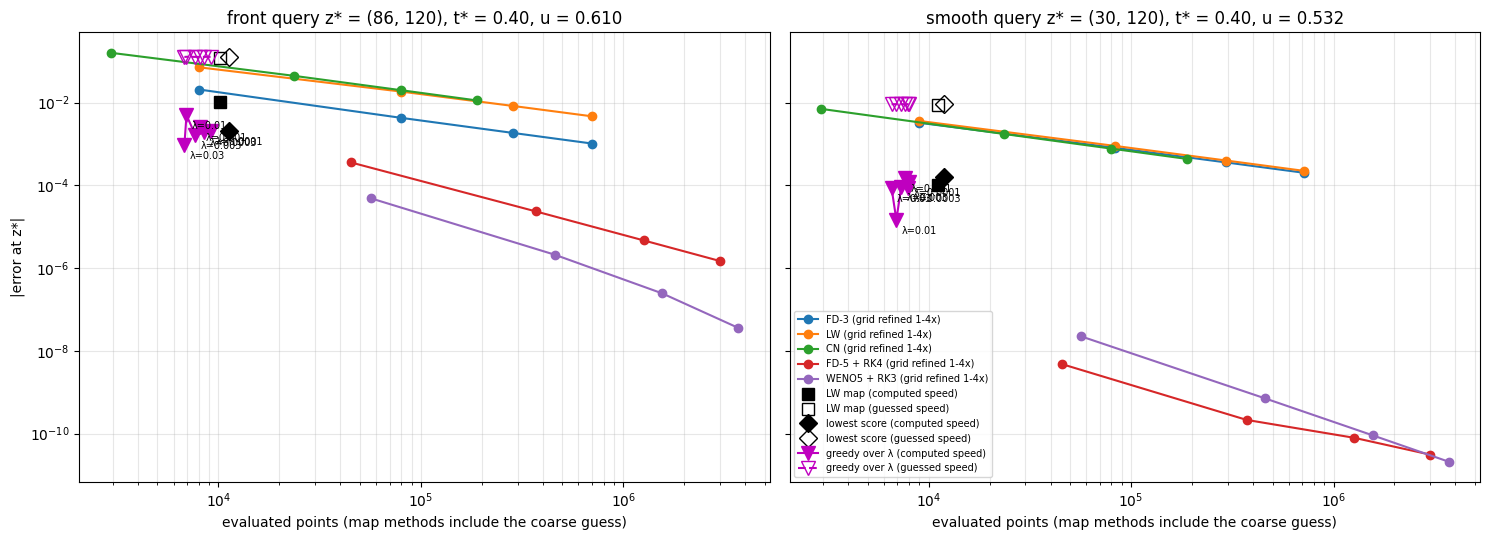

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (name_z, z) in zip(axes, [("front", Z_FRONT), ("smooth", Z_SMOOTH)]):
    d = cmp[cmp["query"] == name_z]
    for i, scheme in enumerate(SCHEMES):
        c = d[d.method == scheme]
        ax.loglog(c.points_total, c.error, "o-", color=f"C{i}", label=f"{scheme} (grid refined 1-4x)")
    for j, (name, mk) in enumerate([("LW map", "s"), ("lowest score", "D")]):
        r = d[d.method == name].iloc[0]
        ax.loglog(r.points_total, r.error_live2, mk, color="k", ms=9, label=f"{name} (computed speed)")
        ax.loglog(r.points_total, r.error_guess, mk, color="k", ms=9, mfc="none", label=f"{name} (guessed speed)")
    g = d[d.method == "greedy"].sort_values("lam")
    ax.loglog(g.points_total, g.error_live2, "v-", color="m", ms=10, label="greedy over λ (computed speed)")
    ax.loglog(g.points_total, g.error_guess, "v--", color="m", ms=10, mfc="none", label="greedy over λ (guessed speed)")
    for _, r in g.iterrows():
        ax.annotate(f"λ={r.lam:g}", (r.points_total, r.error_live2), fontsize=7, xytext=(4, -10), textcoords="offset points")
    ax.set_xlabel("evaluated points (map methods include the coarse guess)"); ax.grid(True, which="both", alpha=0.3)
    ax.set_title(f"{name_z} query z* = {z}, t* = {z[1] * dt:.2f}, u = {Ug(z):.3f}")
axes[0].set_ylabel("|error at z*|"); axes[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(os.path.join("results_shock", "comparison.png"), dpi=120); plt.show()